# Chapter 11: Matrix Calculus — Interactive Coding & Exercise Companion

**Book**: *Mathematics for Artificial Intelligence* · **Chapter 11** (`chapter11-matrix-calculus`)  
**Environment**: `conda activate usao` (`numpy`, `scipy`, `matplotlib`, `torch`)

---

### What You Will Learn & Verify in This Notebook
1. **Part I — Gradients, Jacobians, Matrix-Free VJP & Multivariable Taylor Series (Exercises 1–6)**:
   - **Exercise 1**: Gradient of quadratic form $f(\mathbf{x}) = \mathbf{x}^\top A\mathbf{x} + \mathbf{b}^\top\mathbf{x} + c$ ($A=A^\top$): $\nabla_{\mathbf{x}} f(\mathbf{x}) = 2A\mathbf{x} + \mathbf{b}$.
   - **Exercise 2**: Diagonal Jacobian of element-wise exponential $\frac{\partial\exp(\mathbf{x})}{\partial\mathbf{x}} = \operatorname{diag}(\exp(\mathbf{x}))$.
   - **Exercise 3**: Neural network layer chain rule $\mathbf{y} = \sigma(W\mathbf{x} + \mathbf{b})$: $\frac{\partial\mathbf{y}}{\partial\mathbf{x}} = \operatorname{diag}(\sigma'(\mathbf{z}))W$, $\frac{\partial\mathbf{y}}{\partial\mathbf{b}} = \operatorname{diag}(\sigma'(\mathbf{z}))$, and weight outer-product gradient $\nabla_W\mathcal{L} = \bar{\mathbf{z}}\mathbf{x}^\top$.
   - **Exercise 4**: Least-squares loss $\mathcal{L}(\mathbf{w}) = \frac{1}{2}\|\mathbf{y} - X\mathbf{w}\|_2^2$: $\nabla_{\mathbf{w}}\mathcal{L} = X^\top(X\mathbf{w} - \mathbf{y})$ and constant Hessian $\nabla_{\mathbf{w}}^2\mathcal{L} = X^\top X \succeq 0$.
   - **Exercise 5**: Matrix-free Vector–Jacobian Product (VJP) $\mathbf{v}^\top J$ in $\mathcal{O}(N)$ vs. $\mathcal{O}(N^2)$ explicit Jacobian formation for Softmax $\mathbf{p}\odot(\mathbf{v} - (\mathbf{p}^\top\mathbf{v})\mathbf{1})$.
   - **Exercise 6**: Second-order Taylor approximation of $f(\mathbf{x}) = \log(1 + e^{x_0} + e^{x_1})$ around $\mathbf{x}_0 = [0, 0]^\top$: $T_2(\mathbf{x}) = \log 3 + \frac{1}{3}(x_0 + x_1) + \frac{1}{9}(x_0^2 - x_0 x_1 + x_1^2)$ and $\mathcal{O}(\|\mathbf{x}\|_2^3)$ cubic remainder scaling.
2. **Part II — Transformer Attention Adjoints, Diffusion Score, GPTQ Hessian & HVP Lab (Exercises 7–9 & Lab)**:
   - **Exercise 7**: Complete hand-derived backward pass $(\bar{V}, \bar{P}, \bar{S}, \bar{Q}, \bar{K})$ for scaled dot-product self-attention $Y = \operatorname{softmax}_{\text{row}}(QK^\top/\sqrt{d_k})V$ verified against PyTorch autograd.
   - **Exercise 8**: Diffusion score network $s_\theta(\mathbf{x}_t, t) = W_\theta\phi(\mathbf{x}_t) + \mathbf{b}_\theta$ parameter gradients and input Jacobian $\frac{\partial s_\theta}{\partial\mathbf{x}_t} = W_\theta J_\phi(\mathbf{x}_t)$.
   - **Exercise 9**: Post-training quantization loss $L(W_q) = \|XW - XW_q\|_F^2$ gradient $\nabla_\Delta L = 2X^\top X\Delta$ and GPTQ column-wise inverse-Hessian weight compensation.
   - **Bonus Lab**: Pearlmutter's Double-Backprop Hessian–Vector Product (HVP) $H\mathbf{v} = \nabla_\theta(\nabla_\theta\mathcal{L}^\top\mathbf{v})$ in $\mathcal{O}(N)$ memory.


In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
torch.set_default_dtype(torch.float64)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)


NumPy version: 2.4.6
PyTorch version: 2.10.0+cu128


---
## Part I: Gradients, Jacobians, Matrix-Free VJP & Taylor Series (Exercises 1–6)

### Exercises 1, 2 & 3: Quadratic Form Gradient, Element-Wise Jacobian & Layer Backpropagation
1. **Exercise 1**: For $f(\mathbf{x}) = \mathbf{x}^\top A\mathbf{x} + \mathbf{b}^\top\mathbf{x} + c$ with $A = A^\top \in \mathbb{R}^{N\times N}$,
   $$\nabla_{\mathbf{x}} f(\mathbf{x}) = (A + A^\top)\mathbf{x} + \mathbf{b} = 2A\mathbf{x} + \mathbf{b}.$$
2. **Exercise 2**: For $\mathbf{f}(\mathbf{x}) = [\exp(x_0), \dots, \exp(x_{N-1})]^\top$,
   $$J_{\mathbf{f}}(\mathbf{x}) = \frac{\partial\mathbf{f}}{\partial\mathbf{x}} = \operatorname{diag}(\exp(\mathbf{x})) \in \mathbb{R}^{N\times N}.$$
3. **Exercise 3**: For a single neural network layer $\mathbf{y} = \sigma(W\mathbf{x} + \mathbf{b})$ with $\mathbf{z} = W\mathbf{x} + \mathbf{b} \in \mathbb{R}^M$ and $\sigma'(\mathbf{z}) = \mathbf{y}\odot(1 - \mathbf{y})$:
   $$\frac{\partial\mathbf{y}}{\partial\mathbf{x}} = \operatorname{diag}(\sigma'(\mathbf{z}))W \in \mathbb{R}^{M\times N}, \qquad \frac{\partial\mathbf{y}}{\partial\mathbf{b}} = \operatorname{diag}(\sigma'(\mathbf{z})) \in \mathbb{R}^{M\times M},$$
   and for an upstream scalar loss $\mathcal{L}$ with $\bar{\mathbf{y}} = \nabla_{\mathbf{y}}\mathcal{L}$ and pre-activation adjoint $\bar{\mathbf{z}} = \bar{\mathbf{y}}\odot\sigma'(\mathbf{z})$:
   $$\nabla_{\mathbf{x}}\mathcal{L} = W^\top\bar{\mathbf{z}}, \qquad \nabla_W\mathcal{L} = \bar{\mathbf{z}}\mathbf{x}^\top, \qquad \nabla_{\mathbf{b}}\mathcal{L} = \bar{\mathbf{z}}.$$


[Ex 1] ||grad_autograd - (2Ax + b)||_2     = 8.88e-16
[Ex 2] ||J_autograd - diag(exp(x))||_F     = 0.00e+00
[Ex 3] ||dy/dx_auto - diag(sigma')W||_F    = 0.00e+00
[Ex 3] ||dy/db_auto - diag(sigma')||_F     = 0.00e+00
[Ex 3] ||x.grad - W^T z_bar||_2            = 1.37e-16
[Ex 3] ||W.grad - z_bar x^T||_F            = 1.13e-16
[Ex 3] ||b.grad - z_bar||_2                = 5.55e-17


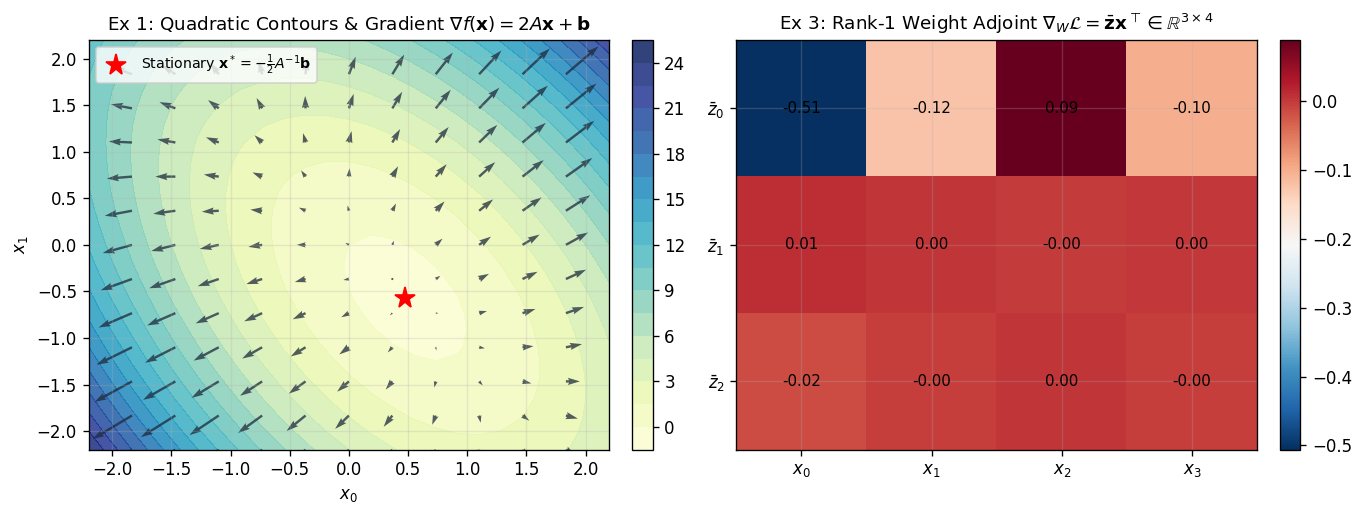

In [2]:
torch.manual_seed(0)

# Exercise 1: Quadratic form f(x) = x^T A x + b^T x + c
M_rand = torch.randn(4, 4)
A = 0.5 * (M_rand + M_rand.T)
b = torch.randn(4)
c = 1.5
x1 = torch.randn(4, requires_grad=True)
f_val = x1 @ A @ x1 + b @ x1 + c
f_val.backward()
grad_ex1_analytical = 2.0 * (A @ x1.detach()) + b
print(f"[Ex 1] ||grad_autograd - (2Ax + b)||_2     = {torch.norm(x1.grad - grad_ex1_analytical).item():.2e}")

# Exercise 2: Element-wise exponential Jacobian
x2 = torch.randn(5, requires_grad=True)
J_ex2_auto = torch.autograd.functional.jacobian(lambda v: torch.exp(v), x2)
J_ex2_exact = torch.diag(torch.exp(x2.detach()))
print(f"[Ex 2] ||J_autograd - diag(exp(x))||_F     = {torch.norm(J_ex2_auto - J_ex2_exact).item():.2e}")

# Exercise 3: Sigmoid layer Jacobians and parameter/input adjoints
M_out, N_in = 3, 4
W = torch.randn(M_out, N_in, requires_grad=True)
bias = torch.randn(M_out, requires_grad=True)
x3 = torch.randn(N_in, requires_grad=True)
y_bar = torch.randn(M_out)

y = torch.sigmoid(W @ x3 + bias)
loss = y @ y_bar
loss.backward()

yd = y.detach()
sigma_prime = yd * (1.0 - yd)
J_yx_auto = torch.autograd.functional.jacobian(lambda v: torch.sigmoid(W.detach() @ v + bias.detach()), x3.detach())
J_yb_auto = torch.autograd.functional.jacobian(lambda v: torch.sigmoid(W.detach() @ x3.detach() + v), bias.detach())
J_yx_exact = torch.diag(sigma_prime) @ W.detach()
J_yb_exact = torch.diag(sigma_prime)

z_bar = y_bar * sigma_prime
dx_exact = W.detach().T @ z_bar
dW_exact = torch.outer(z_bar, x3.detach())
db_exact = z_bar

print(f"[Ex 3] ||dy/dx_auto - diag(sigma')W||_F    = {torch.norm(J_yx_auto - J_yx_exact).item():.2e}")
print(f"[Ex 3] ||dy/db_auto - diag(sigma')||_F     = {torch.norm(J_yb_auto - J_yb_exact).item():.2e}")
print(f"[Ex 3] ||x.grad - W^T z_bar||_2            = {torch.norm(x3.grad - dx_exact).item():.2e}")
print(f"[Ex 3] ||W.grad - z_bar x^T||_F            = {torch.norm(W.grad - dW_exact).item():.2e}")
print(f"[Ex 3] ||b.grad - z_bar||_2                = {torch.norm(bias.grad - db_exact).item():.2e}")

# Visualize Exercise 1 Quadratic Level Sets & Gradient Field + Exercise 3 Outer-Product Weight Gradient
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

A2 = np.array([[2.0, 0.8], [0.8, 1.2]])
b2 = np.array([-1.0, 0.6])
gx, gy = np.meshgrid(np.linspace(-2.2, 2.2, 25), np.linspace(-2.2, 2.2, 25))
pts = np.stack([gx, gy], axis=-1)
Z = np.einsum("...i,ij,...j->...", pts, A2, pts) + pts @ b2
U = 2.0 * (pts @ A2[:, 0]) + b2[0]
V_vec = 2.0 * (pts @ A2[:, 1]) + b2[1]
x_star = -0.5 * np.linalg.solve(A2, b2)

cs = axes[0].contourf(gx, gy, Z, levels=18, cmap="YlGnBu", alpha=0.85)
plt.colorbar(cs, ax=axes[0], fraction=0.046, pad=0.04)
axes[0].quiver(gx[::2, ::2], gy[::2, ::2], U[::2, ::2], V_vec[::2, ::2], color="#1e293b", alpha=0.75)
axes[0].plot(x_star[0], x_star[1], "r*", markersize=13, label=r"Stationary $\mathbf{x}^* = -\frac{1}{2}A^{-1}\mathbf{b}$")
axes[0].set_title(r"Ex 1: Quadratic Contours & Gradient $\nabla f(\mathbf{x}) = 2A\mathbf{x}+\mathbf{b}$")
axes[0].set_xlabel(r"$x_0$")
axes[0].set_ylabel(r"$x_1$")
axes[0].legend(loc="upper left", fontsize=8.5)

im = axes[1].imshow(dW_exact.numpy(), cmap="RdBu_r", aspect="auto")
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
for i in range(M_out):
    for j in range(N_in):
        axes[1].text(j, i, f"{dW_exact[i, j].item():.2f}", ha="center", va="center", color="black", fontsize=9)
axes[1].set_xticks(range(N_in))
axes[1].set_xticklabels([rf"$x_{j}$" for j in range(N_in)])
axes[1].set_yticks(range(M_out))
axes[1].set_yticklabels([rf"$\bar{{z}}_{i}$" for i in range(M_out)])
axes[1].set_title(r"Ex 3: Rank-1 Weight Adjoint $\nabla_W\mathcal{L} = \bar{\mathbf{z}}\mathbf{x}^\top \in \mathbb{R}^{3\times 4}$")

plt.tight_layout()
plt.show()


---
### Exercises 4, 5 & 6: Least-Squares Hessian, Matrix-Free Softmax VJP & Multivariable Taylor Series
1. **Exercise 4**: For $\mathcal{L}(\mathbf{w}) = \frac{1}{2}\|\mathbf{y} - X\mathbf{w}\|_2^2$:
   $$\nabla_{\mathbf{w}}\mathcal{L}(\mathbf{w}) = X^\top(X\mathbf{w} - \mathbf{y}), \qquad \nabla_{\mathbf{w}}^2\mathcal{L}(\mathbf{w}) = X^\top X \succeq 0.$$
2. **Exercise 5**: For $\mathbf{p} = \operatorname{softmax}(\mathbf{z}) \in \mathbb{R}^N$, the full Jacobian $J = \operatorname{diag}(\mathbf{p}) - \mathbf{p}\mathbf{p}^\top \in \mathbb{R}^{N\times N}$ takes $\mathcal{O}(N^2)$ time and memory, whereas the matrix-free Vector–Jacobian Product (VJP) takes $\mathcal{O}(N)$:
   $$\mathbf{v}^\top J = \mathbf{p} \odot \big(\mathbf{v} - (\mathbf{p}^\top\mathbf{v})\mathbf{1}\big).$$
3. **Exercise 6**: For $f(\mathbf{x}) = \log(1 + e^{x_0} + e^{x_1})$ around $\mathbf{x}_0 = [0, 0]^\top$:
   $$f(\mathbf{0}) = \log 3, \qquad \nabla f(\mathbf{0}) = \begin{bmatrix} 1/3 \\ 1/3 \end{bmatrix}, \qquad \nabla^2 f(\mathbf{0}) = \frac{1}{9}\begin{bmatrix} 2 & -1 \\ -1 & 2 \end{bmatrix},$$
   $$T_2(\mathbf{x}) = \log 3 + \frac{1}{3}(x_0 + x_1) + \frac{1}{9}(x_0^2 - x_0 x_1 + x_1^2).$$


[Ex 4] ||grad_auto - X^T(Xw - y)||_2       = 0.00e+00
[Ex 4] ||Hess_auto - X^T X||_F             = 9.92e-16
[Ex 4] Eigenvalues of X^T X (>= 0)         = [ 1.0768  4.9515  9.6732 13.1713]
[Ex 5] ||v^T J_full - p*(v - (p^T v)1)||_2 = 1.65e-17
[Ex 6] Empirical log-log remainder slopes  = T1: 2.001 (theory 2.0), T2: 2.992 (theory 3.0)


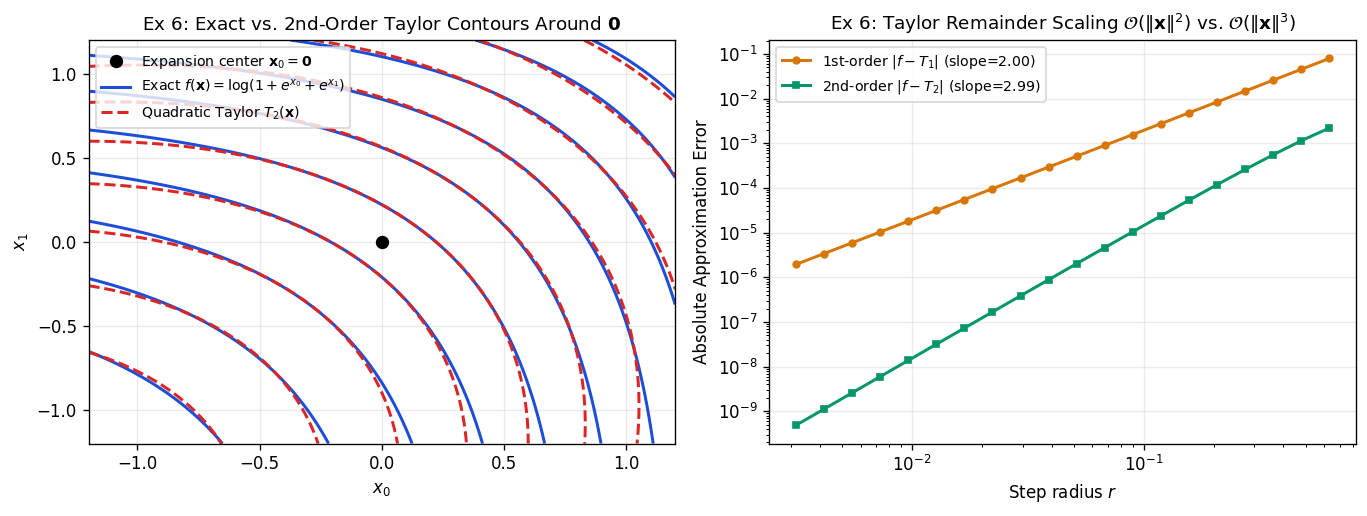

In [3]:
rng = np.random.default_rng(42)

# Exercise 4: Least-squares gradient and constant Hessian X^T X
X4 = torch.tensor(rng.standard_normal((12, 4)))
y4 = torch.tensor(rng.standard_normal(12))
w4 = torch.tensor(rng.standard_normal(4), requires_grad=True)
loss_ls = 0.5 * torch.sum((y4 - X4 @ w4) ** 2)
loss_ls.backward()
grad_ls_exact = X4.T @ (X4 @ w4.detach() - y4)
H_ls_auto = torch.autograd.functional.hessian(lambda v: 0.5 * torch.sum((y4 - X4 @ v) ** 2), w4.detach())
H_ls_exact = X4.T @ X4
print(f"[Ex 4] ||grad_auto - X^T(Xw - y)||_2       = {torch.norm(w4.grad - grad_ls_exact).item():.2e}")
print(f"[Ex 4] ||Hess_auto - X^T X||_F             = {torch.norm(H_ls_auto - H_ls_exact).item():.2e}")
print(f"[Ex 4] Eigenvalues of X^T X (>= 0)         = {np.linalg.eigvalsh(H_ls_exact.numpy())}")

# Exercise 5: Matrix-free O(N) Softmax VJP vs O(N^2) explicit Jacobian
z5 = rng.standard_normal(8)
v5 = rng.standard_normal(8)
p5 = np.exp(z5 - np.max(z5)) / np.sum(np.exp(z5 - np.max(z5)))
J_full5 = np.diag(p5) - np.outer(p5, p5)
vjp_full5 = v5 @ J_full5
vjp_fast5 = p5 * (v5 - np.dot(p5, v5))
print(f"[Ex 5] ||v^T J_full - p*(v - (p^T v)1)||_2 = {np.linalg.norm(vjp_full5 - vjp_fast5):.2e}")

# Exercise 6: Second-order Taylor approximation of f(x) = log(1 + e^x0 + e^x1)
f6 = lambda x: np.log(1.0 + np.exp(x[0]) + np.exp(x[1]))
T1 = lambda x: np.log(3.0) + (x[0] + x[1]) / 3.0
T2 = lambda x: np.log(3.0) + (x[0] + x[1]) / 3.0 + (x[0]**2 - x[0]*x[1] + x[1]**2) / 9.0

radii = np.logspace(-2.5, -0.2, 20)
err_t1, err_t2 = [], []
for r in radii:
    pt = np.array([r, -0.5 * r])
    err_t1.append(abs(f6(pt) - T1(pt)))
    err_t2.append(abs(f6(pt) - T2(pt)))
slope_t1 = np.polyfit(np.log10(radii[:10]), np.log10(err_t1[:10]), 1)[0]
slope_t2 = np.polyfit(np.log10(radii[:10]), np.log10(err_t2[:10]), 1)[0]
print(f"[Ex 6] Empirical log-log remainder slopes  = T1: {slope_t1:.3f} (theory 2.0), T2: {slope_t2:.3f} (theory 3.0)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Left plot: Ex 6 True vs 2nd-order Taylor contours
g0, g1 = np.meshgrid(np.linspace(-1.2, 1.2, 80), np.linspace(-1.2, 1.2, 80))
F_true = np.log(1.0 + np.exp(g0) + np.exp(g1))
F_t2 = np.log(3.0) + (g0 + g1) / 3.0 + (g0**2 - g0 * g1 + g1**2) / 9.0
levels = np.linspace(0.6, 1.9, 10)
c1 = axes[0].contour(g0, g1, F_true, levels=levels, colors="#1d4ed8", linewidths=1.8)
c2 = axes[0].contour(g0, g1, F_t2, levels=levels, colors="#dc2626", linestyles="--", linewidths=1.8)
axes[0].plot(0, 0, "ko", markersize=7, label=r"Expansion center $\mathbf{x}_0 = \mathbf{0}$")
axes[0].plot([], [], color="#1d4ed8", lw=1.8, label=r"Exact $f(\mathbf{x}) = \log(1+e^{x_0}+e^{x_1})$")
axes[0].plot([], [], color="#dc2626", lw=1.8, ls="--", label=r"Quadratic Taylor $T_2(\mathbf{x})$")
axes[0].set_title(r"Ex 6: Exact vs. 2nd-Order Taylor Contours Around $\mathbf{0}$")
axes[0].set_xlabel(r"$x_0$")
axes[0].set_ylabel(r"$x_1$")
axes[0].legend(loc="upper left", fontsize=8.5)

# Right plot: Ex 6 Taylor remainder log-log scaling
axes[1].loglog(radii, err_t1, "o-", color="#d97706", lw=1.8, markersize=4, label=rf"1st-order $|f - T_1|$ (slope={slope_t1:.2f})")
axes[1].loglog(radii, err_t2, "s-", color="#059669", lw=1.8, markersize=4, label=rf"2nd-order $|f - T_2|$ (slope={slope_t2:.2f})")
axes[1].set_title(r"Ex 6: Taylor Remainder Scaling $\mathcal{O}(\|\mathbf{x}\|^2)$ vs. $\mathcal{O}(\|\mathbf{x}\|^3)$")
axes[1].set_xlabel(r"Step radius $r$")
axes[1].set_ylabel(r"Absolute Approximation Error")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Part II: Transformer Attention Adjoints, Diffusion Score, GPTQ & HVP Lab (Exercises 7–9 & Lab)

### Exercise 7: Complete Backward Pass of Scaled Dot-Product Self-Attention
For $S = \frac{QK^\top}{\sqrt{d_k}} \in \mathbb{R}^{N\times N}$, $P = \operatorname{softmax}_{\text{row}}(S) \in \mathbb{R}^{N\times N}$, and $Y = PV \in \mathbb{R}^{N\times d_k}$ with upstream gradient $\bar{Y} = \nabla_Y\mathcal{L}$:
$$\bar{V} = P^\top\bar{Y}, \qquad \bar{P} = \bar{Y}V^\top, \qquad \bar{S} = P \odot \big(\bar{P} - \operatorname{rowsum}(\bar{P}\odot P)\big),$$
$$\bar{Q} = \frac{1}{\sqrt{d_k}}\bar{S}K, \qquad \bar{K} = \frac{1}{\sqrt{d_k}}\bar{S}^\top Q.$$


[Ex 7] ||V.grad - V_bar||_F = 0.00e+00
[Ex 7] ||P.grad - P_bar||_F = 0.00e+00
[Ex 7] ||S.grad - S_bar||_F = 2.08e-16
[Ex 7] ||Q.grad - Q_bar||_F = 2.02e-16
[Ex 7] ||K.grad - K_bar||_F = 2.59e-16


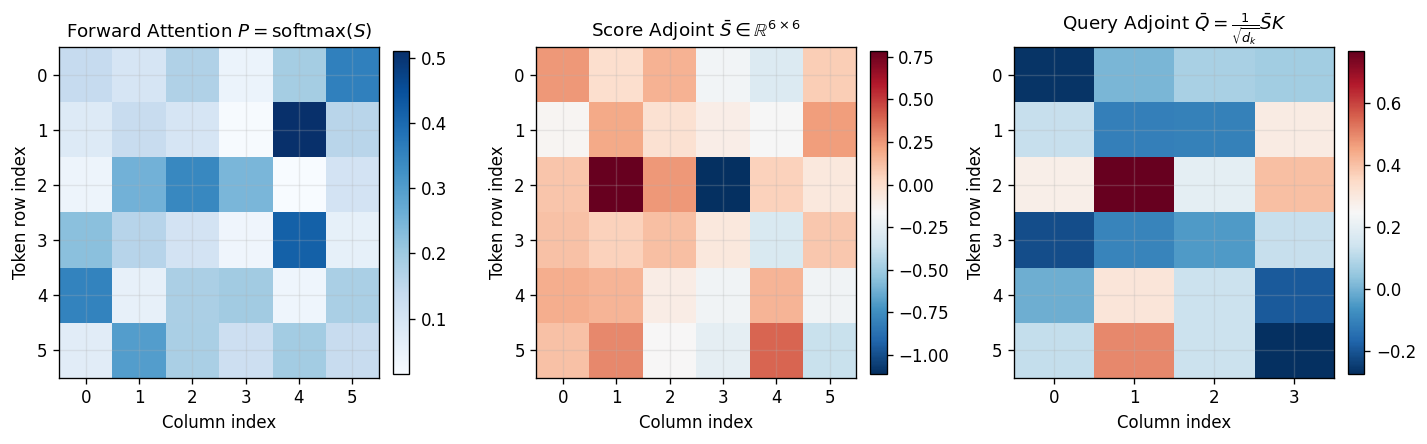

In [4]:
torch.manual_seed(7)
N_seq, d_k = 6, 4
Q = torch.randn(N_seq, d_k, requires_grad=True)
K = torch.randn(N_seq, d_k, requires_grad=True)
V = torch.randn(N_seq, d_k, requires_grad=True)
Y_bar = torch.randn(N_seq, d_k)

# Forward pass with intermediate retention
S = (Q @ K.T) / (d_k ** 0.5)
S.retain_grad()
P = torch.softmax(S, dim=-1)
P.retain_grad()
Y = P @ V
loss_attn = (Y * Y_bar).sum()
loss_attn.backward()

# Manual backward equations from Exercise 7
Pd = P.detach()
V_bar = Pd.T @ Y_bar
P_bar = Y_bar @ V.detach().T
S_bar = Pd * (P_bar - (P_bar * Pd).sum(dim=-1, keepdim=True))
Q_bar = (S_bar @ K.detach()) / (d_k ** 0.5)
K_bar = (S_bar.T @ Q.detach()) / (d_k ** 0.5)

print(f"[Ex 7] ||V.grad - V_bar||_F = {torch.norm(V.grad - V_bar).item():.2e}")
print(f"[Ex 7] ||P.grad - P_bar||_F = {torch.norm(P.grad - P_bar).item():.2e}")
print(f"[Ex 7] ||S.grad - S_bar||_F = {torch.norm(S.grad - S_bar).item():.2e}")
print(f"[Ex 7] ||Q.grad - Q_bar||_F = {torch.norm(Q.grad - Q_bar).item():.2e}")
print(f"[Ex 7] ||K.grad - K_bar||_F = {torch.norm(K.grad - K_bar).item():.2e}")

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8))
mats = [(Pd.numpy(), r"Forward Attention $P = \mathrm{softmax}(S)$", "Blues"),
        (S_bar.numpy(), r"Score Adjoint $\bar{S} \in \mathbb{R}^{6\times 6}$", "RdBu_r"),
        (Q_bar.numpy(), r"Query Adjoint $\bar{Q} = \frac{1}{\sqrt{d_k}}\bar{S}K$", "RdBu_r")]
for ax, (mat, title, cmap) in zip(axes, mats):
    im = ax.imshow(mat, cmap=cmap, aspect="auto")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title)
    ax.set_xlabel("Column index")
    ax.set_ylabel("Token row index")
plt.tight_layout()
plt.show()


---
### Exercises 8 & 9 + Bonus Lab: Diffusion Score Jacobian, GPTQ Hessian Compensation & Pearlmutter HVP
1. **Exercise 8 (Diffusion Score Network $s_\theta(\mathbf{x}_t, t) = W_\theta\phi(\mathbf{x}_t) + \mathbf{b}_\theta$)**:
   $$\nabla_{\mathbf{b}_\theta}\mathcal{L} = \bar{\mathbf{s}}, \qquad \nabla_{W_\theta}\mathcal{L} = \bar{\mathbf{s}}\,\phi(\mathbf{x}_t)^\top, \qquad \frac{\partial s_\theta}{\partial\mathbf{x}_t} = W_\theta J_\phi(\mathbf{x}_t) \in \mathbb{R}^{D\times D}.$$
2. **Exercise 9 (GPTQ Quantization Loss $L(W_q) = \|XW - XW_q\|_F^2$ with $W_q = W + \Delta$)**:
   $$\nabla_\Delta L = 2X^\top X\Delta, \qquad H = 2X^\top X, \qquad \Delta\mathbf{w}_{>q} = -\frac{q(w_q)-w_q}{[H^{-1}]_{qq}}[H^{-1}]_{>q,q}.$$
3. **Bonus Lab (Pearlmutter Double-Backprop HVP)**:
   $$H\mathbf{v} = \nabla_{\mathbf{x}}\big((\nabla_{\mathbf{x}} f(\mathbf{x}))^\top\mathbf{v}\big).$$


[Ex 8] ||W_theta.grad - s_bar phi^T||_F    = 0.00e+00
[Ex 8] ||b_theta.grad - s_bar||_2          = 0.00e+00
[Ex 8] ||ds/dx_auto - W_theta J_phi||_F    = 6.32e-16
[Ex 9] ||Delta.grad - 2 X^T X Delta||_F    = 5.04e-14
[Ex 9] Quarter-step grid loss: Naive = 10.5253 -> GPTQ = 8.9818
[Lab ] ||HVP_double_backprop - H_full v||_2 = 7.69e-16


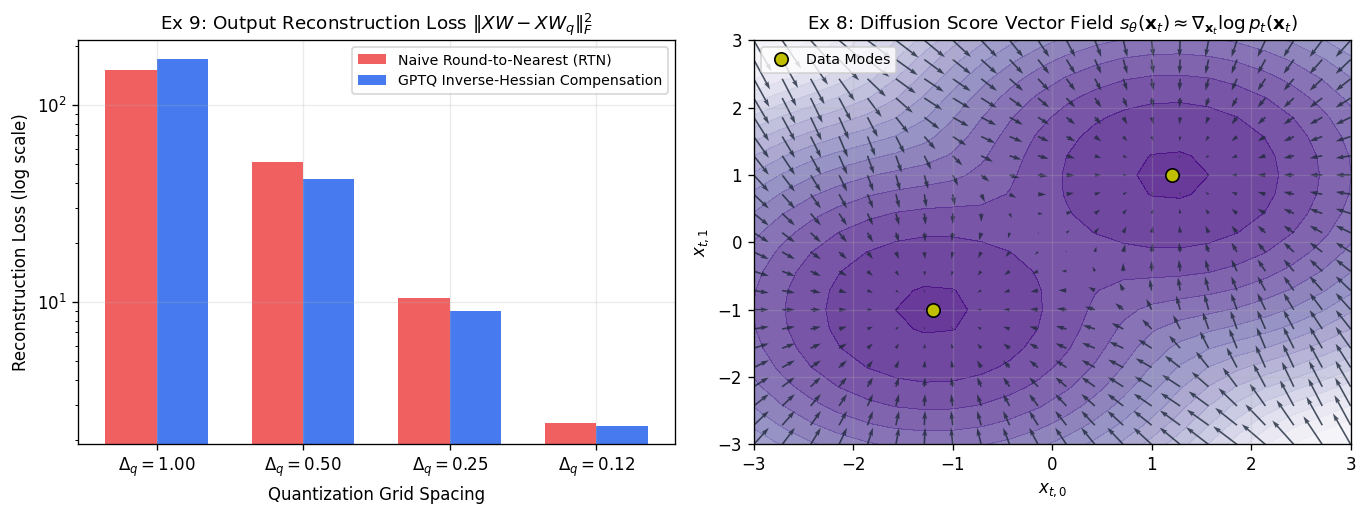

In [5]:
torch.manual_seed(12)

# Exercise 8: Diffusion Score Network parameter gradients and input Jacobian
D_dim, d_feat = 4, 5
W_th = torch.randn(D_dim, d_feat, requires_grad=True)
b_th = torch.randn(D_dim, requires_grad=True)
U_phi = torch.randn(d_feat, D_dim)
xt = torch.randn(D_dim, requires_grad=True)
s_bar = torch.randn(D_dim)

phi_xt = torch.tanh(U_phi @ xt)
s_out = W_th @ phi_xt + b_th
(s_out @ s_bar).backward()

dW_th_exact = torch.outer(s_bar, phi_xt.detach())
db_th_exact = s_bar
J_phi = torch.diag(1.0 - phi_xt.detach() ** 2) @ U_phi
J_score_exact = W_th.detach() @ J_phi
J_score_auto = torch.autograd.functional.jacobian(
    lambda x: W_th.detach() @ torch.tanh(U_phi @ x) + b_th.detach(), xt.detach()
)
print(f"[Ex 8] ||W_theta.grad - s_bar phi^T||_F    = {torch.norm(W_th.grad - dW_th_exact).item():.2e}")
print(f"[Ex 8] ||b_theta.grad - s_bar||_2          = {torch.norm(b_th.grad - db_th_exact).item():.2e}")
print(f"[Ex 8] ||ds/dx_auto - W_theta J_phi||_F    = {torch.norm(J_score_auto - J_score_exact).item():.2e}")

# Exercise 9: Quantization gradient 2 X^T X Delta and GPTQ vs Naive Rounding across bit-widths
X9 = torch.randn(64, 8)
W9 = torch.randn(8, 4)
Delta = (0.05 * torch.randn(8, 4)).requires_grad_(True)
L_quant = torch.sum((X9 @ W9 - X9 @ (W9 + Delta)) ** 2)
L_quant.backward()
grad_Delta_exact = 2.0 * (X9.T @ X9 @ Delta.detach())
print(f"[Ex 9] ||Delta.grad - 2 X^T X Delta||_F    = {torch.norm(Delta.grad - grad_Delta_exact).item():.2e}")

H_gptq = 2.0 * (X9.T @ X9) + 1e-6 * torch.eye(8)
scales = [1.0, 2.0, 4.0, 8.0]  # grid step = 1 / scale
losses_naive, losses_gptq = [], []
for sc in scales:
    q_fn = lambda v: torch.round(v * sc) / sc
    W_naive = q_fn(W9)
    W_gptq = W9.clone()
    for q in range(8):
        H_inv_sub = torch.linalg.inv(H_gptq[q:, q:])
        wq_row = q_fn(W_gptq[q, :])
        err_row = (W_gptq[q, :] - wq_row) / H_inv_sub[0, 0]
        W_gptq[q, :] = wq_row
        if q < 7:
            W_gptq[q+1:, :] -= torch.outer(H_inv_sub[1:, 0], err_row)
    l_n = torch.sum((X9 @ W9 - X9 @ W_naive) ** 2).item()
    l_g = torch.sum((X9 @ W9 - X9 @ W_gptq) ** 2).item()
    losses_naive.append(l_n)
    losses_gptq.append(l_g)

print(f"[Ex 9] Quarter-step grid loss: Naive = {losses_naive[2]:.4f} -> GPTQ = {losses_gptq[2]:.4f}")

# Bonus Lab: Pearlmutter Double-Backprop HVP vs Full Hessian
x_hvp = torch.randn(6, requires_grad=True)
v_hvp = torch.randn(6)
f_nl = lambda x: torch.sum(torch.log(1.0 + torch.exp(x @ A[:4, :4].repeat(2, 2)[:6, :6])))
g_hvp = torch.autograd.grad(f_nl(x_hvp), x_hvp, create_graph=True)[0]
hvp_fast = torch.autograd.grad(torch.dot(g_hvp, v_hvp), x_hvp)[0]
H_full_nl = torch.autograd.functional.hessian(f_nl, x_hvp.detach())
print(f"[Lab ] ||HVP_double_backprop - H_full v||_2 = {torch.norm(hvp_fast - H_full_nl @ v_hvp).item():.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

x_idx = np.arange(len(scales))
width = 0.35
axes[0].bar(x_idx - width/2, losses_naive, width, color="#ef4444", alpha=0.85, label="Naive Round-to-Nearest (RTN)")
axes[0].bar(x_idx + width/2, losses_gptq, width, color="#2563eb", alpha=0.85, label="GPTQ Inverse-Hessian Compensation")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels([rf"$\Delta_q = {1/s:.2f}$" for s in scales])
axes[0].set_yscale("log")
axes[0].set_title(r"Ex 9: Output Reconstruction Loss $\|XW - XW_q\|_F^2$")
axes[0].set_xlabel("Quantization Grid Spacing")
axes[0].set_ylabel("Reconstruction Loss (log scale)")
axes[0].legend(loc="upper right", fontsize=8.5)

# Right subplot: Diffusion score field s_theta(x) = -x / sigma^2 for a 2D bimodal Gaussian mixture
xg, yg = np.meshgrid(np.linspace(-3.0, 3.0, 22), np.linspace(-3.0, 3.0, 22))
c_a, c_b = np.array([-1.2, -1.0]), np.array([1.2, 1.0])
var = 0.65
p_a = np.exp(-((xg - c_a[0])**2 + (yg - c_a[1])**2) / (2 * var))
p_b = np.exp(-((xg - c_b[0])**2 + (yg - c_b[1])**2) / (2 * var))
density = 0.5 * (p_a + p_b)
w_a = 0.5 * p_a / (density + 1e-12)
w_b = 0.5 * p_b / (density + 1e-12)
score_x = -(w_a * (xg - c_a[0]) + w_b * (xg - c_b[0])) / var
score_y = -(w_a * (yg - c_a[1]) + w_b * (yg - c_b[1])) / var

axes[1].contourf(xg, yg, np.log(density + 1e-6), levels=16, cmap="Purples", alpha=0.8)
axes[1].quiver(xg, yg, score_x, score_y, color="#1e293b", alpha=0.8)
axes[1].plot([c_a[0], c_b[0]], [c_a[1], c_b[1]], "yo", markersize=8, markeredgecolor="k", label="Data Modes")
axes[1].set_title(r"Ex 8: Diffusion Score Vector Field $s_\theta(\mathbf{x}_t) \approx \nabla_{\mathbf{x}_t}\log p_t(\mathbf{x}_t)$")
axes[1].set_xlabel(r"$x_{t,0}$")
axes[1].set_ylabel(r"$x_{t,1}$")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()
